# File input and validation

Read a one-column file and report the valid count, sum, range and number of rejected records.

The supplied CSV has a header and short, unquoted single-field rows. It contains four small integers and two nonnumeric tokens. Keep data-reading errors distinct from bad fields. A rejected row should be counted exactly once and excluded from every numeric statistic. General CSV with embedded commas or quoted newlines needs a CSV parser.

Scanner controls line-by-line input. A scan error, an unparseable field and an empty data file are separate cases.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.go`

```go
package main

import (
	"bufio"
	"fmt"
	"os"
	"strconv"
	"strings"
)

func main() {
	f, err := os.Open("readings.csv")
	if err != nil {
		panic(err)
	}
	defer f.Close()
	scan := bufio.NewScanner(f)
	if !scan.Scan() {
		panic("missing header")
	}
	count, sum, lo, hi, rejected := 0, 0, 0, 0, 0
	for scan.Scan() {
		v, err := strconv.Atoi(strings.TrimSpace(scan.Text()))
		if err != nil {
			rejected++
			continue
		}
		if count == 0 || v < lo {
			lo = v
		}
		if count == 0 || v > hi {
			hi = v
		}
		sum += v
		count++
	}
	if err := scan.Err(); err != nil {
		panic(err)
	}
	if count == 0 {
		panic("no numeric rows")
	}
	fmt.Println(count, sum, lo, hi, rejected)
}
```

## Execute the native listing

Scanner controls line-by-line input. A scan error, an unparseable field and an empty data file are separate cases. Trace the result and error at the point where each function returns. Slice length, map lookup status and channel synchronisation are explicit parts of the interface.

In [2]:
x = ["2", "5", "NA", "9", "bad", "5"]
vals = [int(v) for v in x if v.lstrip("+-").isdigit()]
expected = np.asarray(
    [len(vals), sum(vals), min(vals), max(vals), len(x) - len(vals)], dtype=float
)
engine, stdout = run_native(here / "native.go")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: Go
Native stdout: 4 21 2 9 2
Largest absolute difference: 0


## Read the output

The first statistic counts accepted rows and the last counts rejected rows. Together they must account for all six input observations. The sum and extrema refer to accepted rows only. The marks show the independent Python reference at each position.

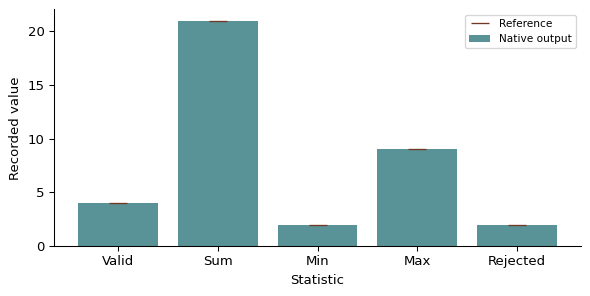

In [3]:
labels = ["Valid", "Sum", "Min", "Max", "Rejected"]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Statistic", ylabel="Recorded value")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

The first statistic counts accepted rows and the last counts rejected rows. Together they must account for all six input observations. The sum and extrema refer to accepted rows only.

## Exercise

Insert another malformed row, rerun and compare the counts. Define an explicit policy for a file with no valid rows.

## References

[The Go Programming Language Specification](https://go.dev/ref/spec)